In [ ]:
#This notebook will be used for the extracted dataset exploration and cleaning
#Will start by downloadng pandas and loading the dataset

In [1]:
import pandas as pd
df = pd.read_parquet("../data/processed/pml_mda.parquet")
df.shape, df.dtypes

((118152, 8),
 clv_nodo                str
 timestamp    datetime64[us]
 fecha        datetime64[us]
 hora                  int64
 pml                 float64
 pml_ene             float64
 pml_per             float64
 pml_cng             float64
 dtype: object)

In [ ]:
#Shape and types of data look good. 
#clv_nodo = Node code: which of the 9 Monclova grid points the price belongs to 
#timestamp = date + time, the exact hour the price applies to, built it from fecha + hora
#fecha = operating day
#hora = operating hour
#pml	= precio marginal local in MXN per MWh, what 1 megawatt-hour of electricity costs at that node in that hour
#pml_ene = energy component, the system-wide auction price
#pml_per = losses component, the cost of energy lost as heat in the wires getting there. Can be negative.
#pml_cng = congestion component, extra cost (or discount) when transmission lines are full. Usually 0, can be negative.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 118152 entries, 0 to 118151
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   clv_nodo   118152 non-null  str           
 1   timestamp  118152 non-null  datetime64[us]
 2   fecha      118152 non-null  datetime64[us]
 3   hora       118152 non-null  int64         
 4   pml        118152 non-null  float64       
 5   pml_ene    118152 non-null  float64       
 6   pml_per    118152 non-null  float64       
 7   pml_cng    118152 non-null  float64       
dtypes: datetime64[us](2), float64(4), int64(1), str(1)
memory usage: 8.2 MB


In [3]:
df.head()

,clv_nodo,timestamp,fecha,hora,pml,pml_ene,pml_per,pml_cng
0,06AEO-115,2024-01-01 00:00:00,2024-01-01,1,279.92,370.71,-43.69,-47.1
1,06AEO-115,2024-01-01 01:00:00,2024-01-01,2,279.21,311.75,-32.54,0.0
2,06AEO-115,2024-01-01 02:00:00,2024-01-01,3,274.23,305.52,-31.28,0.0
3,06AEO-115,2024-01-01 03:00:00,2024-01-01,4,264.01,294.23,-30.22,0.0
4,06AEO-115,2024-01-01 04:00:00,2024-01-01,5,243.44,267.66,-24.22,0.0


In [4]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#We have no duplicated values, no missing values so all looks good to go, but checking duplicated price per hour per node just to be extra sure

In [5]:
dup_mask = df.duplicated(subset=["clv_nodo", "timestamp"], keep=False)
print("Duplicate node-hour rows:", dup_mask.sum())
df[dup_mask].sort_values(["clv_nodo", "timestamp"])

Duplicate node-hour rows: 0


,clv_nodo,timestamp,fecha,hora,pml,pml_ene,pml_per,pml_cng


In [ ]:
#All good, now viewing one node on a graphic way for deeper data exploration

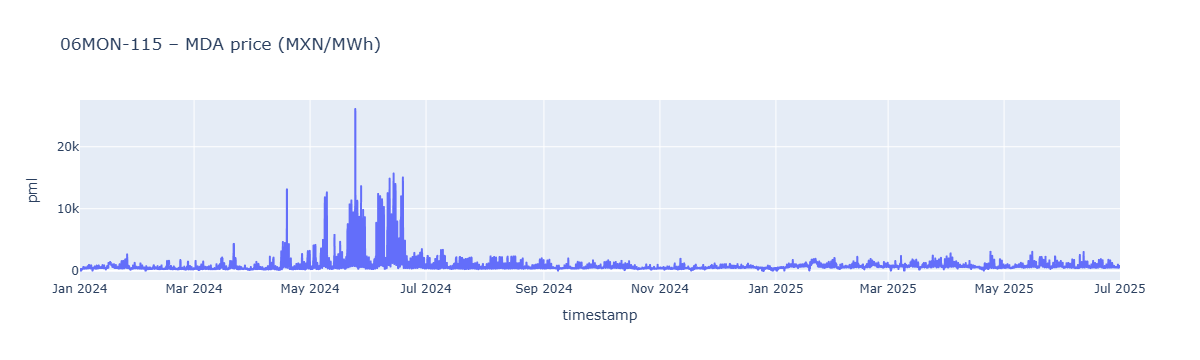

In [7]:
import plotly.express as px
one = df[df["clv_nodo"] == "06MON-115"]
px.line(one, x="timestamp", y="pml", title="06MON-115 – MDA price (MXN/MWh)")

In [ ]:
Daily pattern: what’s the average price by hour of day? When is the peak?
Weekly pattern: weekdays vs. weekends?
Seasonal pattern: summer vs. winter (average by month)?
Spikes: how high do prices go, how often, and when? Are they system-wide or at one node?
Components: which component drives most of the price, and the spikes? How often is congestion non-zero?
Nodes: how similar are the 9 nodes (correlation)? Does the 400 kV node behave differently?
Negative or zero prices: do they exist? Are they errors or real?